In [3]:
# Import all basic functions
import onnx
import onnxruntime as ort
import ml_dtypes
import numpy as np
import h5py
import torch

# Import config
from config import load_config

# data generation
from generate_data.datagen import (
    sample_ambient_points,
    sample_around_points,
    repeat_points_to_match,
)

# model generation
from construct.construct import (
    ensure_base_model,
    ensure_extra_outputs
)


# execution code
from execute.optimization_loop import optimization_loop, NewtonRaphson
import importlib
import sys

In [56]:
# 1. Reload the parent module
importlib.reload(sys.modules['execute.optimization_loop'])
importlib.reload(sys.modules['generate_data.datagen'])

 

# 2. Re-import the specific functions/classes into memory
from execute.optimization_loop import optimization_loop, NewtonRaphson
from generate_data.datagen import (
    sample_ambient_points,
    sample_around_points,
    repeat_points_to_match,
)

In [2]:


# Load config
cfg = load_config("configs/tiny_llama.toml")

# Re-use all existing models
force = False


# makes sure that our base model is loaded
ensure_base_model(cfg, force=force, verbose=False)

2026-09-15 11:00:44,532 huggingface_hub.utils._http [WARNING] - Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


config.json:   0%|          | 0.00/560 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 4.40GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/129 [00:00<?, ?B/s]

W0915 11:00:56.295000 681870 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W0915 11:00:56.296000 681870 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W0915 11:00:56.297000 681870 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W0915 11:00:56.297000 681870 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::deform_conv2d
/nfs-share/pa511/.local/share/uv/python/cpython-3.11.10-linux-x86_64-gnu/lib/python3.11/copyreg.py:105: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


Base model exported -> onnx_models/tiny_llama/base_model.onnx


In [4]:
extra_outputs = [sublayer.output for sublayer in cfg.sublayers]
model_path = ensure_extra_outputs(cfg, extra_outputs, force=True)

Extra outputs model generated -> onnx_models/tiny_llama/base_model_extra_outputs.onnx


In [58]:

# Load model
graph_path = sub_graphs_pullbacks[0]
model = onnx.load(graph_path)

# Data


# Define output session
sess_options = ort.SessionOptions()

# Very Important --- will cause errors if missing
sess_options.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_BASIC
sess_options.intra_op_num_threads = 8  # pick a value <= your usable core count
out_sess = ort.InferenceSession(
    str(sub_graphs[0][0]),
    sess_options=sess_options,
    providers=["CUDAExecutionProvider"],
)


# Get all output and input names
output_names = {o.name for o in out_sess.get_outputs()}
input_names = {o.name for o in out_sess.get_inputs()}
input_names = [i for i in input_names]


# Get the correct data for this approach
# Sample lots of points in a wide range of spaces

x = sample_ambient_points(
    batch= cfg.batch,
    seq= cfg.seq,
    dim=cfg.d_model,
    low=-1,
    high=1,
).astype(ml_dtypes.bfloat16)



In [ ]:
out = out_sess.run(
    None,
    {input_names[0]: x},
)
y0 = sample_around_points(x, n_samples=1000, max_radius=1e-3).astype(ml_dtypes.bfloat16)
print(np.isnan(out).any(), np.isnan(y0).any())
# Sample around all of these points



False False


In [60]:

# Define gradient session
grad_sess = ort.InferenceSession(
    str(graph_path), sess_options=sess_options, providers=["CUDAExecutionProvider"]
)

optim = NewtonRaphson(1e-10, dtype=ml_dtypes.bfloat16)


y_final, loss_history = optimization_loop(
    grad_sess,
    x=x,
    target=out[0],
    y0=y0,
    input_name="add_6",
    steps=1000,
    optimizer=optim,
)



2026-09-02 15:21:24.595136871 [W:onnxruntime:, transformer_memcpy.cc:74 ApplyImpl] 5 Memcpy nodes are added to the graph Extracted from {main_graph} for CUDAExecutionProvider. It might have negative impact on performance (including unable to run CUDA graph). Set session_options.log_severity_level=1 to see the detail logs before this message.
2026-09-02 15:21:24.595493241 [W:onnxruntime:, session_state.cc:1168 VerifyEachNodeIsAssignedToAnEp] Some nodes were not assigned to the preferred execution providers which may or may not have an negative impact on performance. e.g. ORT explicitly assigns shape related ops to CPU to improve perf.
2026-09-02 15:21:24.595497771 [W:onnxruntime:, session_state.cc:1170 VerifyEachNodeIsAssignedToAnEp] Rerunning with verbose output on a non-minimal build will show node assignments.
  0%|          | 0/10 [00:00<?, ?it/s]

isnan y False


 10%|█         | 1/10 [00:03<00:28,  3.17s/it]

isnan y False


 20%|██        | 2/10 [00:06<00:25,  3.17s/it]

...

 80%|████████  | 8/10 [00:25<00:06,  3.17s/it]

isnan y False


 90%|█████████ | 9/10 [00:28<00:03,  3.17s/it]

isnan y False


100%|██████████| 10/10 [00:31<00:00,  3.17s/it]


In [ ]:
import platform

import matplotlib.pyplot as plt

x32 = x.astype(np.float32)
fx = out_sess.run(None, {input_names[0]: x})[0].astype(np.float32)

dx_list = []
dfx_list = []
for s in range(y_final.shape[0]):
    y_s = y_final[s]
    fy_s = out_sess.run(None, {input_names[0]: y_s})[0].astype(np.float32)
    dx_list.append(np.linalg.norm(y_s.astype(np.float32) - x32, axis=-1))
    dfx_list.append(np.linalg.norm(fy_s - fx, axis=-1))

dx = np.concatenate([d.ravel() for d in dx_list])
dfx = np.concatenate([d.ravel() for d in dfx_list])



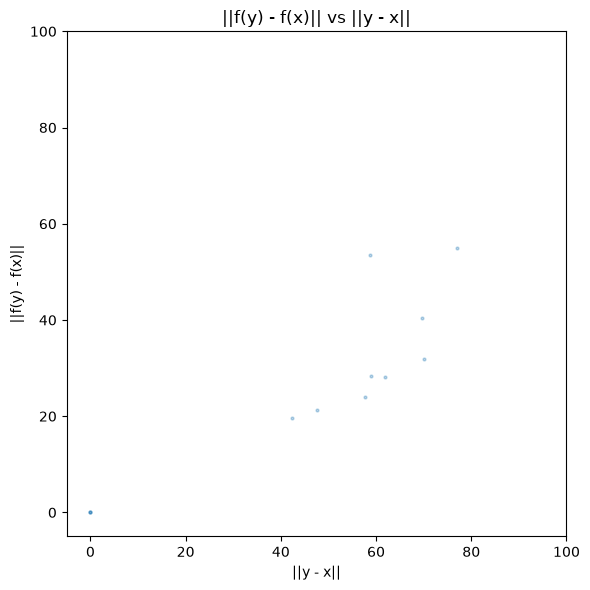

In [64]:
plt.figure(figsize=(6, 6))
plt.scatter(dx, dfx, s=4, alpha=0.3)
plt.xlabel("||y - x||")
plt.ylabel("||f(y) - f(x)||")
plt.title("||f(y) - f(x)|| vs ||y - x||")
plt.xlim(-5, 100)
plt.ylim(-5, 100)
plt.tight_layout()
plt.savefig("lipschitz_scatter.png", dpi=150)